# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ruchi74/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*



The action playbook helps editors decide which content items to review first. Each item should include a priority, a reason code, and a suggested action.

Priority is a review order, not a guarantee that a page is declining. Because the Week 6 model did not outperform the majority-class baseline on F1 score, these recommendations are experimental and require human review.

### Reason codes

- **CHECK_TREND:** Review recent impressions, clicks, and trend data to confirm whether performance is declining.
- **REFRESH_CONTENT:** Consider updating outdated or incomplete content after editorial review.
- **CHECK_SEARCH_INTENT:** Check whether the content still matches the audience's search intent.
- **VERIFY_DATA:** Review missing, unusual, or unreliable metrics before making a decision.
- **HUMAN_REVIEW:** Do not recommend a content change until an editor verifies the evidence.

In [1]:
import pandas as pd
from pathlib import Path

example_queue = pd.DataFrame([
    {
        "reason_code": "VERIFY_DATA",
        "suggested_action": "Check data quality before deciding",
        "evidence_needed": "Confirm recent metrics are valid",
        "human_review_required": True
    },
    {
        "reason_code": "CHECK_TREND",
        "suggested_action": "Review recent performance changes",
        "evidence_needed": "Compare recent and previous periods",
        "human_review_required": True
    },
    {
        "reason_code": "CHECK_SEARCH_INTENT",
        "suggested_action": "Review content relevance",
        "evidence_needed": "Check whether content meets search intent",
        "human_review_required": True
    },
    {
        "reason_code": "REFRESH_CONTENT",
        "suggested_action": "Consider an editorial refresh",
        "evidence_needed": "Confirm outdated or incomplete information",
        "human_review_required": True
    }
])

example_queue["priority"] = [1, 2, 3, 4]
display(example_queue)

,reason_code,suggested_action,evidence_needed,human_review_required,priority
0,VERIFY_DATA,Check data quality before deciding,Confirm recent metrics are valid,True,1
1,CHECK_TREND,Review recent performance changes,Compare recent and previous periods,True,2
2,CHECK_SEARCH_INTENT,Review content relevance,Check whether content meets search intent,True,3
3,REFRESH_CONTENT,Consider an editorial refresh,Confirm outdated or incomplete information,True,4


In [2]:
example_queue = example_queue.reset_index(drop=True)

# Put priority in the first column
cols = ["priority", "reason_code", "suggested_action",
        "evidence_needed", "human_review_required"]
example_queue = example_queue[cols]

display(example_queue)

,priority,reason_code,suggested_action,evidence_needed,human_review_required
0,1,VERIFY_DATA,Check data quality before deciding,Confirm recent metrics are valid,True
1,2,CHECK_TREND,Review recent performance changes,Compare recent and previous periods,True
2,3,CHECK_SEARCH_INTENT,Review content relevance,Check whether content meets search intent,True
3,4,REFRESH_CONTENT,Consider an editorial refresh,Confirm outdated or incomplete information,True


In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*



The playbook is an experimental decision-support tool for content editors. It helps organize content items for human review and suggests checks based on available performance evidence.

The current Week 6 model achieved 51.6% accuracy and an F1 score of 0.559. The majority-class baseline achieved 51.1% accuracy and an F1 score of 0.676. These results do not establish that the model performs better overall than the baseline.

The example action queue is illustrative and is not generated from real model predictions. Before using a real queue, it must be connected to validated content-level predictions and current performance metrics.

The playbook cannot prove why a page's performance changed, guarantee that a refresh will improve results, or predict Google's ranking algorithm. All suggested actions require human review.

In [4]:
import pandas as pd

example_queue = pd.DataFrame({
    "priority": [1, 2, 3, 4],
    "reason_code": [
        "VERIFY_DATA",
        "CHECK_TREND",
        "CHECK_SEARCH_INTENT",
        "REFRESH_CONTENT"
    ],
    "suggested_action": [
        "Check data quality before deciding",
        "Review recent performance changes",
        "Review content relevance",
        "Consider an editorial refresh"
    ],
    "evidence_needed": [
        "Confirm recent metrics are valid",
        "Compare recent and previous periods",
        "Check whether content meets search intent",
        "Confirm outdated or incomplete information"
    ],
    "human_review_required": [True, True, True, True]
})

display(example_queue)

,priority,reason_code,suggested_action,evidence_needed,human_review_required
0,1,VERIFY_DATA,Check data quality before deciding,Confirm recent metrics are valid,True
1,2,CHECK_TREND,Review recent performance changes,Compare recent and previous periods,True
2,3,CHECK_SEARCH_INTENT,Review content relevance,Check whether content meets search intent,True
3,4,REFRESH_CONTENT,Consider an editorial refresh,Confirm outdated or incomplete information,True


In [5]:
example_queue = pd.DataFrame({
    "priority": [1, 2, 3, 4],
    "reason_code": [
        "VERIFY_DATA",
        "CHECK_TREND",
        "CHECK_SEARCH_INTENT",
        "REFRESH_CONTENT"
    ],
    "suggested_action": [
        "Check data quality before deciding",
        "Review recent performance changes",
        "Review content relevance",
        "Consider an editorial refresh"
    ],
    "evidence_needed": [
        "Confirm recent metrics are valid",
        "Compare recent and previous periods",
        "Check whether content meets search intent",
        "Confirm outdated or incomplete information"
    ],
    "human_review_required": [True, True, True, True]
})

print("Priority values:", example_queue["priority"].tolist())
display(example_queue)

Priority values: [1, 2, 3, 4]


,priority,reason_code,suggested_action,evidence_needed,human_review_required
0,1,VERIFY_DATA,Check data quality before deciding,Confirm recent metrics are valid,True
1,2,CHECK_TREND,Review recent performance changes,Compare recent and previous periods,True
2,3,CHECK_SEARCH_INTENT,Review content relevance,Check whether content meets search intent,True
3,4,REFRESH_CONTENT,Consider an editorial refresh,Confirm outdated or incomplete information,True


In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*



Every suggested action must be reviewed by a human editor before implementation.

### Human-review rules
- Verify data quality and recent performance before taking action.
- Check whether the content is outdated, incomplete, or mismatched with search intent.
- Review the expected benefit, cost, and risk of changing the content.
- Record the editor's decision and the reason for approval or rejection.

### What should NOT be automated
- Automatically deleting or publishing content.
- Automatically changing titles, URLs, or important page information.
- Making changes based only on model predictions.
- Claiming that a content refresh will guarantee higher rankings or traffic.

The playbook supports editorial decisions; it does not replace human judgment.

In [7]:
human_review_rules = {
    "Review_required_before_action": True,
    "Automatic_content_deletion": False,
    "Automatic_publishing": False,
    "Changes_based_only_on_prediction": False,
    "Guaranteed_performance_improvement_claims": False
}

for rule, status in human_review_rules.items():
    print(f"{rule}: {status}")

Review_required_before_action: True
Automatic_content_deletion: False
Automatic_publishing: False
Changes_based_only_on_prediction: False
Guaranteed_performance_improvement_claims: False


In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*



The playbook should be monitored regularly to ensure its recommendations remain useful and reliable.

### Monitoring checks
- **Performance:** Track impressions, clicks, CTR, and average position over time.
- **Data quality:** Check for missing values, unusual values, and changes in data availability.
- **Action outcomes:** Compare content performance before and after an editorial change.
- **Model performance:** Recalculate precision, recall, and F1 score using newly reviewed data.

### Retraining triggers
- Model performance drops below an agreed evaluation threshold.
- New data shows meaningful changes in content patterns.
- Data quality or feature distributions change significantly.
- Sufficient newly labelled data becomes available.

Retraining should only happen after evaluation and validation. A performance change does not automatically prove that the model needs retraining.

In [9]:
monitoring_triggers = {
    "Check_content_metrics_regularly": True,
    "Check_missing_or_unusual_data": True,
    "Evaluate_model_with_new_labels": True,
    "Retrain_without_validation": False,
    "Assume_every_performance_drop_requires_retraining": False
}

for trigger, status in monitoring_triggers.items():
    print(f"{trigger}: {status}")

Check_content_metrics_regularly: True
Check_missing_or_unusual_data: True
Evaluate_model_with_new_labels: True
Retrain_without_validation: False
Assume_every_performance_drop_requires_retraining: False


In [10]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*



The notebook exports an example ranked action queue to `work/outputs/` and a visualization to `work/figures/`.

The queue is illustrative and is not generated from real model predictions. The CSV contains no client names, URLs, or private queries and should remain out of version control.

The figure summarizes the number of example actions by reason code. These outputs demonstrate the export workflow and should not be interpreted as evidence of model effectiveness.

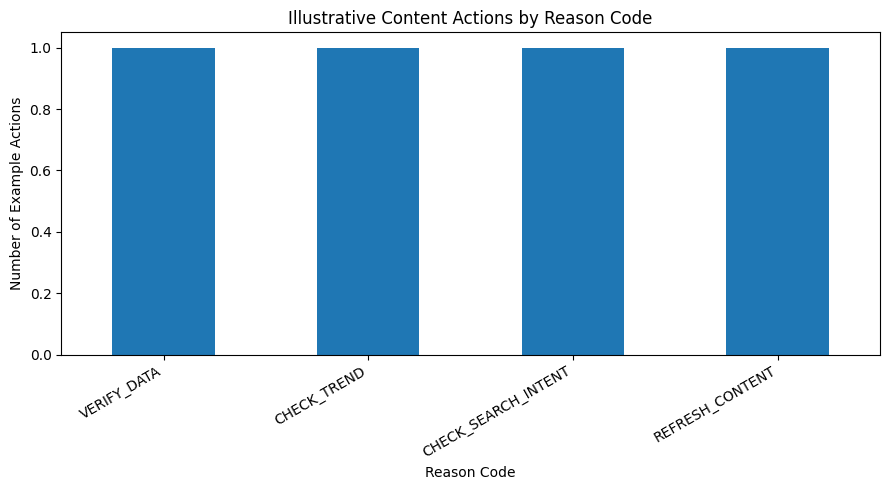

Queue saved to: work/outputs/action_queue_example.csv
Figure saved to: work/figures/example_actions_by_reason.png
Queue is illustrative, not real model output.


In [11]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create output folders
output_dir = Path("work/outputs")
figure_dir = Path("work/figures")

output_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

# Export the illustrative action queue
queue_path = output_dir / "action_queue_example.csv"
example_queue.to_csv(queue_path, index=False)

# Create a figure showing example actions by reason code
reason_counts = example_queue["reason_code"].value_counts()

plt.figure(figsize=(9, 5))
reason_counts.plot(kind="bar")
plt.title("Illustrative Content Actions by Reason Code")
plt.xlabel("Reason Code")
plt.ylabel("Number of Example Actions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

figure_path = figure_dir / "example_actions_by_reason.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Queue saved to:", queue_path)
print("Figure saved to:", figure_path)
print("Queue is illustrative, not real model output.")

In [12]:
from pathlib import Path

required_files = [
    Path("work/outputs/action_queue_example.csv"),
    Path("work/figures/example_actions_by_reason.png")
]

print("SELF-CHECK: EXPORTED FILES")

for file_path in required_files:
    print(f"{file_path}: {'PASS' if file_path.exists() else 'FAIL'}")

print("\nQueue rows:", len(example_queue))
print("All actions require human review:",
      example_queue["human_review_required"].all())
print("Priority values:", example_queue["priority"].tolist())

SELF-CHECK: EXPORTED FILES
work/outputs/action_queue_example.csv: PASS
work/figures/example_actions_by_reason.png: PASS

Queue rows: 4
All actions require human review: True
Priority values: [1, 2, 3, 4]


In [14]:

import pandas as pd
from pathlib import Path

# Load the dataset
url = (
    "https://raw.githubusercontent.com/"
    "Ruchi74/flyrank-ml-internship/main/"
    "data/raw/content_refresh_anonymized.csv"
)

df = pd.read_csv(url)

# Create a content review playbook
playbook = df.copy()

# Calculate impression decline where possible
if {
    "impressions_last_30d",
    "impressions_prev_30d"
}.issubset(playbook.columns):

    previous = playbook["impressions_prev_30d"]
    current = playbook["impressions_last_30d"]

    playbook["impression_change_pct"] = (
        (current - previous) / previous.replace(0, float("nan")) * 100
    )

    def assign_priority(row):
        if pd.isna(row["impression_change_pct"]):
            return "Needs Data Check"
        elif row["impression_change_pct"] <= -20:
            return "High"
        elif row["impression_change_pct"] < 0:
            return "Medium"
        else:
            return "Low"

    playbook["review_priority"] = playbook.apply(
        assign_priority, axis=1
    )

else:
    raise ValueError(
        "Required impression columns are missing from the dataset."
    )

# Add a recommended action
actions = {
    "High": "Review content, search intent, and technical SEO first",
    "Medium": "Check content freshness and traffic trends",
    "Low": "Monitor performance and review routinely",
    "Needs Data Check": "Verify missing or zero baseline impressions"
}

playbook["recommended_action"] = (
    playbook["review_priority"].map(actions)
)

# Show highest-priority pages first
priority_order = {
    "High": 0,
    "Medium": 1,
    "Low": 2,
    "Needs Data Check": 3
}

playbook["_order"] = playbook["review_priority"].map(priority_order)
playbook = playbook.sort_values(
    ["_order", "impression_change_pct"],
    na_position="first"
).drop(columns="_order")

# Save results
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "week7_action_playbook.csv"
playbook.to_csv(output_file, index=False)

print("Week 7 action playbook created successfully!")
print("Total content rows:", len(playbook))
print("\nPriority summary:")
print(playbook["review_priority"].value_counts())
print("\nTop 10 pages for review:")
print(
    playbook[
        ["content_id", "impression_change_pct",
         "review_priority", "recommended_action"]
    ].head(10).to_string(index=False)
)
print("\nSaved to:", output_file)


Week 7 action playbook created successfully!
Total content rows: 30000

Priority summary:
review_priority
High                16305
Low                  6896
Medium               3411
Needs Data Check     3388
Name: count, dtype: int64

Top 10 pages for review:
          content_id  impression_change_pct review_priority                                     recommended_action
content_2da6ae9d0882                 -100.0            High Review content, search intent, and technical SEO first
content_4595e8704e07                 -100.0            High Review content, search intent, and technical SEO first
content_326fa2fa449f                 -100.0            High Review content, search intent, and technical SEO first
content_f0717373e86e                 -100.0            High Review content, search intent, and technical SEO first
content_d8a23b5e10c5                 -100.0            High Review content, search intent, and technical SEO first
content_9042a5355ff7                 -100.0     

## Results and Findings

The action playbook processed 30,000 content records and assigned review priorities based on changes in impressions over the previous and latest 30-day periods.

### Priority Summary

| Priority | Number of pages |
|---|---:|
| High | 16,305 |
| Medium | 3,411 |
| Low | 6,896 |
| Needs Data Check | 3,388 |
| **Total** | **30,000** |

### Findings
- 16,305 pages were classified as high priority because impressions declined by at least 20%.
- 3,411 pages showed a smaller decline and were assigned medium priority.
- 6,896 pages were assigned low priority because impressions did not decline.
- 3,388 pages require data checks because their baseline impressions were missing or zero.
- The top 10 displayed pages had a 100% decline in impressions.

### Conclusion
The action playbook provides a simple way to organize content pages for human review. These priorities are based on observed impression changes, not validated machine-learning predictions. Reviewers should verify the data and investigate possible causes before making content changes. The generated CSV file can be used for further analysis and review planning.

In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check



- [x] Ranked example actions include reason codes and suggested actions.
- [x] Intended use and model limitations are documented.
- [x] Human-review rules and the no-go list are included.
- [x] Monitoring and retraining triggers are documented.
- [x] The example queue CSV and figure are exported.
- [x] The queue is clearly labelled as illustrative, not real model output.
- [x] Model performance claims are cautious and reflect Week 6 results.
- [ ] Notebook runs from top to bottom without errors.
- [ ] Notebook is saved and committed to the GitHub repository.

The remaining checks must be confirmed after running the complete notebook and saving the notebook to the repository.